# How Well Do Weather Conditions and Population Density Explain Dengue Activity in Singapore? (2014-2018)

**Name:** Rayhan  

---

## Introduction

This notebook looks at how weather conditions and national population density are related to reported dengue cases in Singapore from 2014 to 2018.

This is an observational analysis. Correlation can show that two variables move together, but it does not prove that one caused the other.


## Aims/Goals/Objectives

This study answers three questions:

1. How did dengue activity change across months and years?
2. How are rainfall, temperature and relative humidity associated with dengue cases in Singapore from 2014 to 2018?
3. is annual national population density linked to annual dengue incidence?

These questions relate to the topic because weather can affect mosquito breeding, while population density may affect how many people are exposed in the same urban space.

---

## Datasets

| Dataset | Agency | Time scale used | Use in this notebook |
|---|---|---|---|
| [Weekly dengue and dengue haemorrhagic fever cases](https://data.gov.sg/datasets/d_ac1eecf0886ff0bceefbc51556247015/view) | MOH | Weekly, changed to monthly | Dengue outcome |
| [Rainfall - monthly total](https://data.gov.sg/datasets/d_b16d06b83473fdfcc92ed9d37b66ba58/view) | NEA | Monthly | Weather factor |
| [Surface air temperature - monthly mean](https://data.gov.sg/datasets/d_755290a24afe70c8f9e8bcbf9f251573/view) | NEA | Monthly | Weather factor |
| [Relative humidity - monthly mean](https://data.gov.sg/datasets/d_e3b1111a26b2aefef4f386c068d4ca5d/view) | NEA | Monthly | Weather factor |
| [Indicators on population, annual](https://data.gov.sg/datasets/d_3d227e5d9fdec73f3bcadce671c333a6/view) | SingStat | Annual | Population and population density |

Weather and dengue are compared monthly. Population density is only compared annually because it is published annually. repeating one yearly density value twelve times would create a misleading result


In [ ]:
# Importing libraries and loading datasets
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "legend.frameon": False})

COLOURS = {"navy": "#183B56", "teal": "#007C83", "orange": "#E57C23", "red": "#C94C4C", "slate": "#5B6770", "light": "#E8F1F2"}

# If the CSV filenames are renamed, update only this cell.
humidity_df = pd.read_csv("RelativeHumidityMonthlyMean.csv")
temperature_df = pd.read_csv("SurfaceAirTemperatureMonthlyMean.csv")
rainfall_df = pd.read_csv("RainfallMonthlyTotal.csv")
dengue_df = pd.read_csv("WeeklyNumberofDengueandDengueHaemorrhagicFeverCases.csv")
population_df = pd.read_csv("IndicatorsOnPopulationAnnual.csv")


## Data Checking

Before cleaning the data, the next table checks the size, columns, missing values and duplicate rows in every dataset


In [ ]:
#  checking the source datasets
datasets = {
    "Relative humidity": humidity_df,
    "Temperature": temperature_df,
    "Rainfall": rainfall_df,
    "Dengue cases": dengue_df,
    "Population indicators": population_df,
}

data_profile = pd.DataFrame([
    {
        "Dataset": name,
        "Rows": data.shape[0],
        "Columns": data.shape[1],
        "Missing cells": int(data.isna().sum().sum()),
        "Duplicate rows": int(data.duplicated().sum()),
    }
    for name, data in datasets.items()
])

display(data_profile)


,Dataset,Rows,Columns,Missing cells,Duplicate rows
0,Relative humidity,534,2,0,0
1,Temperature,534,2,0,0
2,Rainfall,534,2,0,0
3,Dengue cases,530,4,8,0
4,Population indicators,29,77,0,0


## Data Cleaning and Preparation

### Monthly Weather Data

The weather data is limited to January 2014 to December 2018, converted to dates and renamed clearly. Duplicate rows are removed before merging


In [ ]:
# cleaning the monthly weather datasets
humidity_clean = humidity_df.copy().rename(columns={"mean_rh": "relative_humidity"})
temperature_clean = temperature_df.copy().rename(columns={"mean_temp": "mean_temperature"})
rainfall_clean = rainfall_df.copy().rename(columns={"total_rainfall": "total_rainfall_mm"})

start_date = pd.Timestamp("2014-01-01")
end_date = pd.Timestamp("2018-12-01")

for weather_df in [humidity_clean, temperature_clean, rainfall_clean]:
    weather_df["month"] = pd.to_datetime(weather_df["month"], format="%Y-%m")
    weather_df.drop_duplicates(inplace=True)

humidity_clean = humidity_clean[humidity_clean["month"].between(start_date, end_date)].copy()
temperature_clean = temperature_clean[temperature_clean["month"].between(start_date, end_date)].copy()
rainfall_clean = rainfall_clean[rainfall_clean["month"].between(start_date, end_date)].copy()

weather_check = pd.DataFrame({
    "Dataset": ["Relative humidity", "Temperature", "Rainfall"],
    "Rows after filtering": [len(humidity_clean), len(temperature_clean), len(rainfall_clean)],
    "Missing cells": [
        humidity_clean.isna().sum().sum(),
        temperature_clean.isna().sum().sum(),
        rainfall_clean.isna().sum().sum(),
    ],
})
display(weather_check)


,Dataset,Rows after filtering,Missing cells
0,Relative humidity,60,0
1,Temperature,60,0
2,Rainfall,60,0


### Annual Population Data

The population file stores indicators in rows and years in columns. Only total population and population density are extracted. total population is needed to calculate dengue cases per 100,000 people.


In [ ]:
# Cleaning annual population data
population_clean = population_df.drop_duplicates().copy()
population_series_column = "DataSeries" if "DataSeries" in population_clean.columns else population_clean.columns[0]
population_clean[population_series_column] = population_clean[population_series_column].astype(str).str.strip()

years_used = [2014, 2015, 2016, 2017, 2018]

def extract_population_series(series_name):
    matching_row = population_clean[
        population_clean[population_series_column].str.lower() == series_name.lower()
    ]
    if matching_row.empty:
        raise ValueError(f'Could not find "{series_name}" in the population dataset.')
    return [pd.to_numeric(matching_row.iloc[0][str(year)], errors="coerce") for year in years_used]


population_annual = pd.DataFrame({
    "year": years_used,
    "population_density": extract_population_series("Population Density"),
    "total_population": extract_population_series("Total Population"),
})

display(population_annual)


,year,population_density,total_population
0,2014,7615.0,5469724.0
1,2015,7697.0,5535002.0
2,2016,7797.0,5607283.0
3,2017,7796.0,5612253.0
4,2018,7804.0,5638676.0


### Weekly Dengue Data

The dengue data is weekly. Missing case counts are removed instead of changed to zero. dengue and dengue haemorrhagic fever are combined, then weekly cases are added into monthly totals so they can be compared with weather data.


In [ ]:
#changing weekly dengue records into monthly totals
dengue_clean = dengue_df.copy()
missing_dengue_rows = dengue_clean["number"].isna().sum()
dengue_clean = dengue_clean.dropna(subset=["number"]).copy()

dengue_weekly = dengue_clean.pivot(
    index=["year", "eweek"],
    columns="type_dengue",
    values="number",
).reset_index()
dengue_weekly.columns.name = None
dengue_weekly["total_dengue_cases"] = dengue_weekly["Dengue"] + dengue_weekly["DHF"]

def get_week_start(year, eweek):
    jan_4 = pd.Timestamp(year=int(year), month=1, day=4)
    first_sunday = jan_4 - pd.Timedelta(days=(jan_4.dayofweek + 1) % 7)
    return first_sunday + pd.Timedelta(weeks=int(eweek) - 1)

dengue_weekly["week_start"] = dengue_weekly.apply(
    lambda row: get_week_start(row["year"], row["eweek"]), axis=1
)
dengue_weekly["month"] = (
    (dengue_weekly["week_start"] + pd.Timedelta(days=3))
    .dt.to_period("M")
    .dt.to_timestamp()
)

dengue_monthly = (
    dengue_weekly.groupby("month", as_index=False)
    .agg(
        dengue_cases=("Dengue", "sum"),
        dhf_cases=("DHF", "sum"),
        total_dengue_cases=("total_dengue_cases", "sum"),
        weeks_in_month=("eweek", "count"),
    )
)
dengue_monthly["average_weekly_cases"] = (
    dengue_monthly["total_dengue_cases"] / dengue_monthly["weeks_in_month"]
)
dengue_monthly = dengue_monthly[dengue_monthly["month"].between(start_date, end_date)].copy()

print(f"Rows with missing case counts removed: {missing_dengue_rows}")
display(dengue_monthly.head())


Rows with missing case counts removed: 8


,month,dengue_cases,dhf_cases,total_dengue_cases,weeks_in_month,average_weekly_cases
0,2014-01-01,1886.0,1.0,1887.0,5,377.4
1,2014-02-01,1021.0,3.0,1024.0,4,256.0
2,2014-03-01,868.0,2.0,870.0,4,217.5
3,2014-04-01,1252.0,1.0,1253.0,5,250.6
4,2014-05-01,1435.0,1.0,1436.0,4,359.0


In [86]:
print(dengue_weekly[["Dengue", "DHF"]].isna().sum())

Dengue    0
DHF       0
dtype: int64


### Final Monthly Dataset

All monthly datasets are merged by month. the checks confirm that the final table has one complete row for each month from 2014 to 2018.


In [ ]:
# merging and validating the final monthly dataset
merged_df = (
    dengue_monthly
    .merge(rainfall_clean, on="month", how="inner")
    .merge(temperature_clean, on="month", how="inner")
    .merge(humidity_clean, on="month", how="inner")
    .sort_values("month")
    .reset_index(drop=True)
)
merged_df["year"] = merged_df["month"].dt.year
merged_df["month_name"] = merged_df["month"].dt.strftime("%b")

assert len(merged_df) == 60, "Expected 60 monthly observations."
assert merged_df["month"].is_unique, "Duplicate months found."
assert merged_df.isna().sum().sum() == 0, "Missing values remain after merging."
assert len(population_annual) == 5, "Expected five annual population observations."

print("Validation passed: 60 complete monthly rows and 5 annual population rows.")
display(merged_df.head())


Validation passed: 60 complete monthly rows and 5 annual population rows.


,month,dengue_cases,dhf_cases,total_dengue_cases,weeks_in_month,average_weekly_cases,total_rainfall_mm,mean_temperature,relative_humidity,year,month_name
0,2014-01-01,1886.0,1.0,1887.0,5,377.4,75.4,26.2,78.5,2014,Jan
1,2014-02-01,1021.0,3.0,1024.0,4,256.0,0.2,27.2,74.5,2014,Feb
2,2014-03-01,868.0,2.0,870.0,4,217.5,66.0,27.9,76.0,2014,Mar
3,2014-04-01,1252.0,1.0,1253.0,5,250.6,110.0,28.2,80.0,2014,Apr
4,2014-05-01,1435.0,1.0,1436.0,4,359.0,125.8,28.6,80.2,2014,May


## Descriptive Statistics

The following statistics give a quick overview of the range and variation in the monthly data before answering the research questions.


In [ ]:
# Creating descriptive statistics
columns_to_summarise = [
    "total_dengue_cases",
    "average_weekly_cases",
    "total_rainfall_mm",
    "mean_temperature",
    "relative_humidity",
]

summary_statistics = pd.DataFrame([
    {
        "Variable": column,
        "Mean": np.mean(merged_df[column]),
        "Median": np.median(merged_df[column]),
        "Standard deviation": np.std(merged_df[column], ddof=1),
        "Minimum": np.min(merged_df[column]),
        "Maximum": np.max(merged_df[column]),
    }
    for column in columns_to_summarise
])

display(summary_statistics.round(2))


,Variable,Mean,Median,Standard deviation,Minimum,Maximum
0,total_dengue_cases,812.58,610.00,693.32,136.0,3574.0
1,average_weekly_cases,186.08,152.50,154.47,34.0,714.8
2,total_rainfall_mm,141.92,126.20,79.72,0.2,371.2
3,mean_temperature,28.03,28.20,0.74,26.1,29.4
4,relative_humidity,78.72,78.45,3.31,72.0,86.6


# Section 1: Dengue Trends (RQ1)

RQ1 asks how dengue activity changed over time. this gives the pattern that weather and population density would need to explain.

We will first plot a line graph of monthly dengue cases. A line graph is suitable because the data is ordered by month, so it makes peaks and drops easy to see.


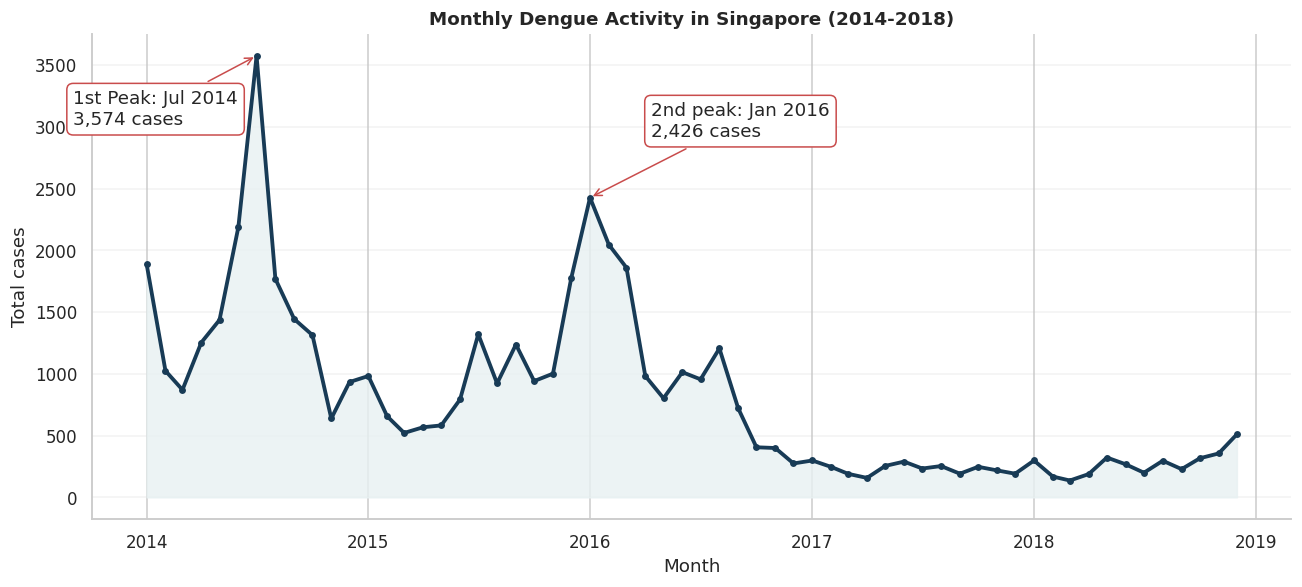

In [ ]:
# creating a line graph for monthly dengue cases
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(
    merged_df["month"],
    merged_df["total_dengue_cases"],
    color=COLOURS["navy"],
    linewidth=2.5,
    marker="o",
    markersize=3.5,
)
ax.fill_between(merged_df["month"], merged_df["total_dengue_cases"], color=COLOURS["light"], alpha=0.8)

peak_row = merged_df.loc[merged_df["total_dengue_cases"].idxmax()]
# show the peak and value
ax.annotate(
    f"1st Peak: {peak_row['month']:%b %Y}\n{peak_row['total_dengue_cases']:,.0f} cases",
    xy=(peak_row["month"], peak_row["total_dengue_cases"]),
    xytext=(-120, -45),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": COLOURS["red"]},
    bbox={"boxstyle": "round,pad=0.35", "fc": "white", "ec": COLOURS["red"]},
)
second_peak_row = merged_df.nlargest(2,"total_dengue_cases").iloc[1]
ax.annotate(
  f"2nd peak: {second_peak_row['month']:%b %Y}\n{second_peak_row['total_dengue_cases']:,.0f} cases",
    xy=(second_peak_row["month"], second_peak_row["total_dengue_cases"]),
    xytext=(40, 40),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": COLOURS["red"]},
    bbox={"boxstyle": "round,pad=0.35", "fc": "white", "ec": COLOURS["red"]},
)

ax.set(title="Monthly Dengue Activity in Singapore (2014-2018)", xlabel="Month", ylabel="Total cases")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


## Insights

The line graph shows that dengue cases changed a lot from month to month. the largest peak was in July 2014 and 2nd largest in Jan 2016. this matters to the research topic because a strong explanation should be able to account for this large change


We will now plot a bar graph to compare annual dengue cases. A bar graph is suitable because it compares separate yearly totals clearly.


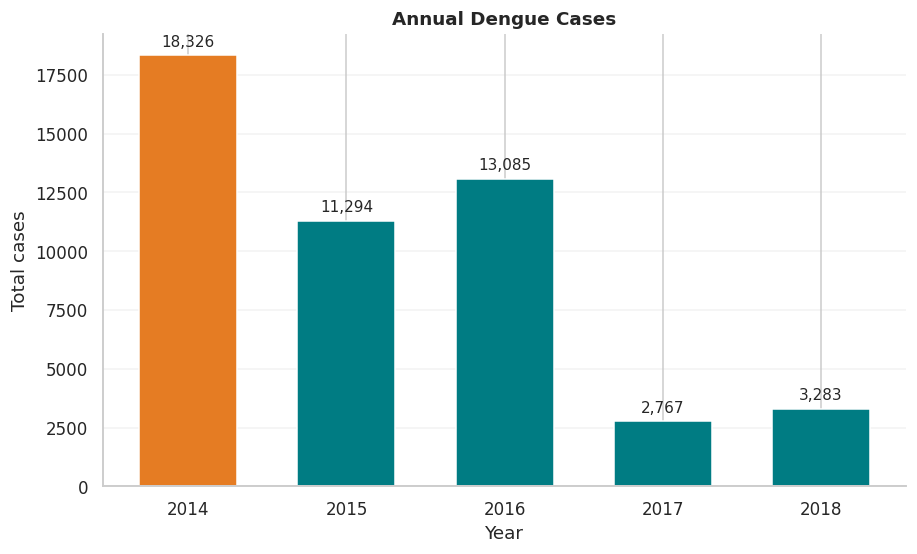

,year,total_dengue_cases
0,2014,18326.0
1,2015,11294.0
2,2016,13085.0
3,2017,2767.0
4,2018,3283.0


In [ ]:
# Creating bar graph for annual dengue cases
annual_cases = merged_df.groupby("year", as_index=False)["total_dengue_cases"].sum()
bar_colours = [COLOURS["orange"] if value == annual_cases["total_dengue_cases"].max() else COLOURS["teal"] for value in annual_cases["total_dengue_cases"]]

fig, ax = plt.subplots(figsize=(8.5, 5.2))
bars = ax.bar(annual_cases["year"].astype(str), annual_cases["total_dengue_cases"], color=bar_colours, width=0.62)
ax.bar_label(bars, labels=[f"{value:,.0f}" for value in annual_cases["total_dengue_cases"]], padding=4, fontsize=10)
ax.set(title="Annual Dengue Cases", xlabel="Year", ylabel="Total cases")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

display(annual_cases)


## Insights

Annual dengue cases fell from 18,326 in 2014 to 3,283 in 2018. This shows a major change in dengue activity, so weather and density should be judged against this change instead of treated as automatic explanations.


# Section 2: Weather and Dengue Activity (RQ2)

RQ2 checks whether rainfall, temperature and humidity are linked to dengue activity. These weather conditions may affect mosquito breeding and survival.

We will first plot a correlation heatmap for the same month. A heatmap is useful because it compares every weather variable on the same correlation scale and prevents focusing on only one result.


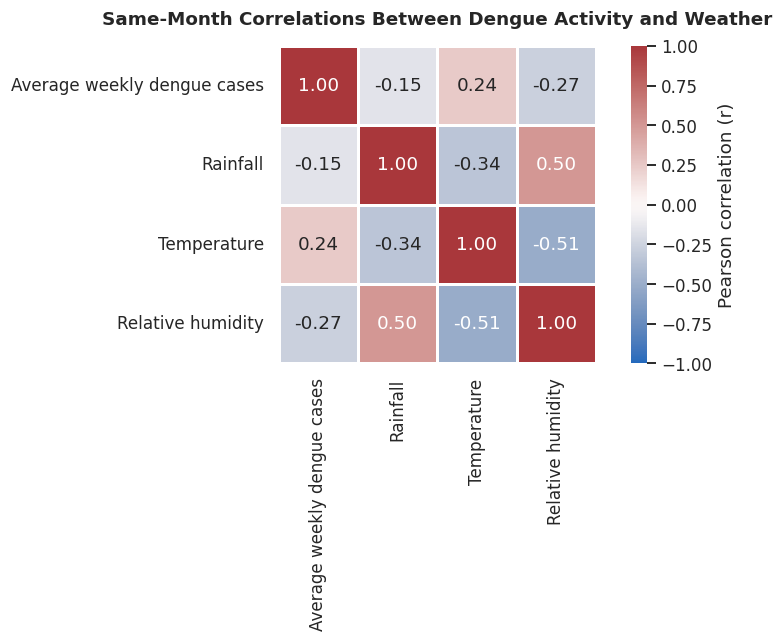

In [ ]:
# Calculating same-month weather correlations
weather_labels = {
    "total_rainfall_mm": "Rainfall",
    "mean_temperature": "Temperature",
    "relative_humidity": "Relative humidity",
}
correlation_columns = ["average_weekly_cases", *weather_labels.keys()]
correlation_matrix = merged_df[correlation_columns].corr()
correlation_matrix = correlation_matrix.rename(index={"average_weekly_cases": "Average weekly dengue cases", **weather_labels}, columns={"average_weekly_cases": "Average weekly dengue cases", **weather_labels})

fig, ax = plt.subplots(figsize=(8.5, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.8,
    cbar_kws={"label": "Pearson correlation (r)"},
    ax=ax,
)
ax.set_title("Same-Month Correlations Between Dengue Activity and Weather", pad=14)
fig.tight_layout()
plt.show()


## Insights

The same-month correlations are weak. This means that no single weather variable in the same month explains much of the dengue pattern on its own.


We will now plot a grouped bar graph to compare weather correlations at the same month, one month earlier and two months earlier. This is useful because mosquito development may take time, so delayed weather may matter more than same-month weather.


Timing,Weather variable,1 month earlier,2 months earlier,Same month
0,Rainfall,-0.075,-0.146,-0.154
1,Relative humidity,-0.158,-0.137,-0.267
2,Temperature,0.269,0.267,0.245


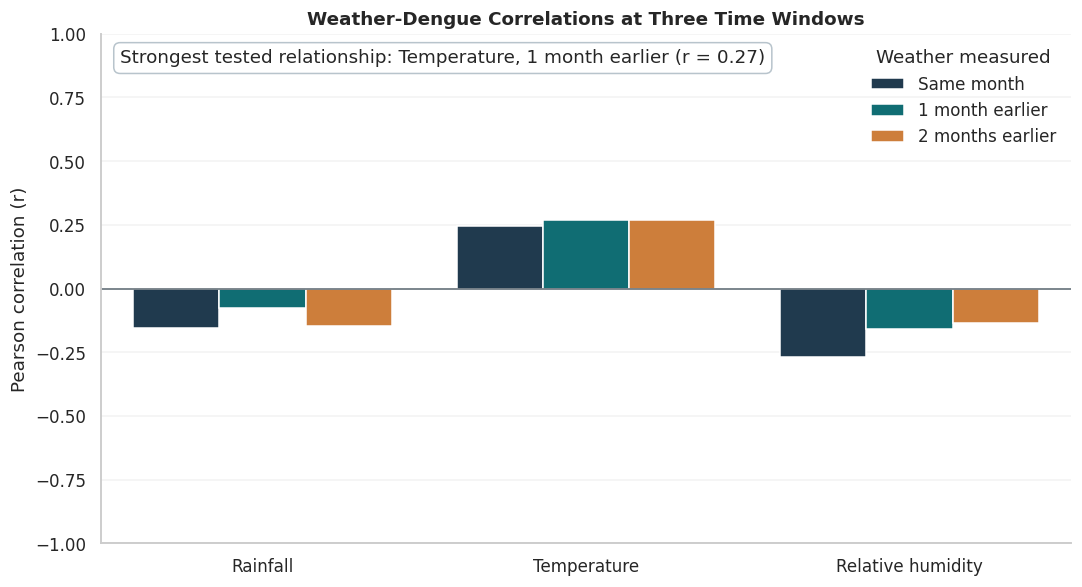

In [ ]:
# Calculating weather correlations with time lags
lagged_df = merged_df.copy()
lag_results = []

for column, label in weather_labels.items():
    for lag in [0, 1, 2]:
        shifted_column = f"{column}_lag_{lag}"
        lagged_df[shifted_column] = lagged_df[column].shift(lag)
        lag_results.append({
            "Weather variable": label,
            "Timing": "Same month" if lag == 0 else f"{lag} month{'s' if lag > 1 else ''} earlier",
            "Correlation": lagged_df["average_weekly_cases"].corr(lagged_df[shifted_column]),
        })

lag_summary_long = pd.DataFrame(lag_results)
lag_summary = lag_summary_long.pivot(index="Weather variable", columns="Timing", values="Correlation").reset_index()
display(lag_summary.round(3))

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(
    data=lag_summary_long,
    x="Weather variable",
    y="Correlation",
    hue="Timing",
    palette=[COLOURS["navy"], COLOURS["teal"], COLOURS["orange"]],
    ax=ax,
)
ax.axhline(0, color=COLOURS["slate"], linewidth=1)
ax.set(ylim=(-1, 1), title="Weather-Dengue Correlations at Three Time Windows", xlabel="", ylabel="Pearson correlation (r)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Weather measured")

strongest_lag = lag_summary_long.loc[lag_summary_long["Correlation"].abs().idxmax()]
ax.text(
    0.02, 0.97,
    f"Strongest tested relationship: {strongest_lag['Weather variable']}, {strongest_lag['Timing']} (r = {strongest_lag['Correlation']:.2f})",
    transform=ax.transAxes, va="top",
    bbox={"boxstyle": "round,pad=0.35", "fc": "white", "ec": "#B8C4CC"},
)
fig.tight_layout()
plt.show()


## Insights

The strongest tested result is mean temperature one month earlier, at about r = 0.27. This is still weak. Weather may matter, but the results do not support weather as a strong stand-alone explanation of monthly dengue cases.


# Section 3: Population Density and Dengue Incidence (RQ3)

RQ3 checks whether national population density is linked to dengue incidence. higher density could mean more people are exposed in the same urban space. however, this is only a national indicator, not a measure of each HDB town.


In [ ]:
# Calculating the annual dengue incidence and population density
annual_analysis = annual_cases.merge(population_annual, on="year", how="inner")
annual_analysis["dengue_cases_per_100k"] = (
    annual_analysis["total_dengue_cases"] / annual_analysis["total_population"] * 100000
)
annual_analysis["density_change_percent"] = annual_analysis["population_density"].pct_change() * 100
annual_analysis["dengue_change_percent"] = annual_analysis["total_dengue_cases"].pct_change() * 100

display(annual_analysis.round(2))


,year,total_dengue_cases,population_density,total_population,dengue_cases_per_100k,density_change_percent,dengue_change_percent
0,2014,18326.0,7615.0,5469724.0,335.04,NaN,NaN
1,2015,11294.0,7697.0,5535002.0,204.05,1.08,-38.37
2,2016,13085.0,7797.0,5607283.0,233.36,1.30,15.86
3,2017,2767.0,7796.0,5612253.0,49.30,-0.01,-78.85
4,2018,3283.0,7804.0,5638676.0,58.22,0.10,18.65


We will now plot a line graph of national population density. this shows how much the density measure itself changed before comparing it with dengue cases


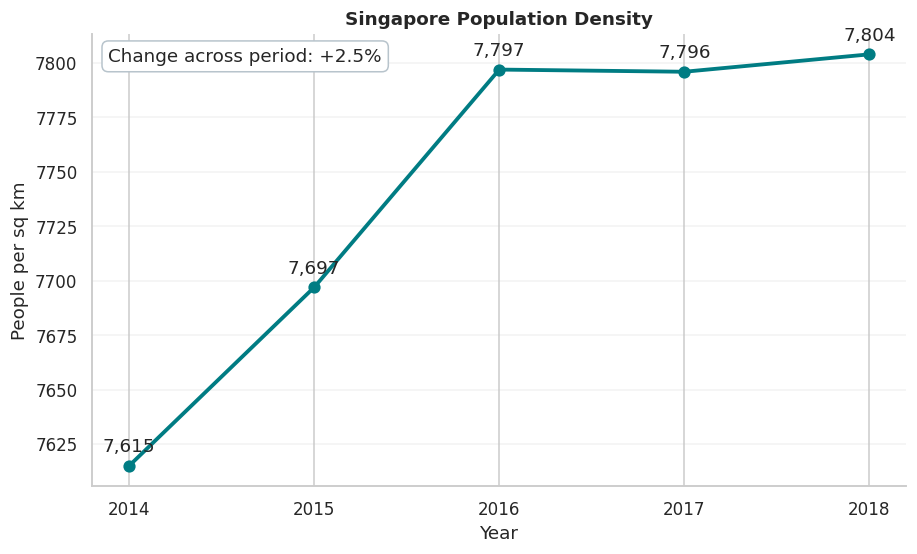

In [ ]:
# Creating a line graph for population density
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.plot(annual_analysis["year"], annual_analysis["population_density"], marker="o", markersize=7, color=COLOURS["teal"], linewidth=2.5)
for _, row in annual_analysis.iterrows():
    ax.annotate(f"{row['population_density']:,.0f}", (row["year"], row["population_density"]), xytext=(0, 9), textcoords="offset points", ha="center")

density_change = (annual_analysis.iloc[-1]["population_density"] / annual_analysis.iloc[0]["population_density"] - 1) * 100
ax.text(0.02, 0.97, f"Change across period: +{density_change:.1f}%", transform=ax.transAxes, va="top", bbox={"boxstyle": "round,pad=0.35", "fc": "white", "ec": "#B8C4CC"})
ax.set(title="Singapore Population Density", xlabel="Year", ylabel="People per sq km", xticks=annual_analysis["year"])
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


## Insights

National population density rose gradually from 2014 to 2018. it did not change nearly as much as dengue cases, so it is unlikely to explain the dengue pattern by itself


We will now plot an indexed line graph comparing dengue cases and population density. Both values start at 2014 = 100, which makes their percentage changes comparable without using two y-axes.


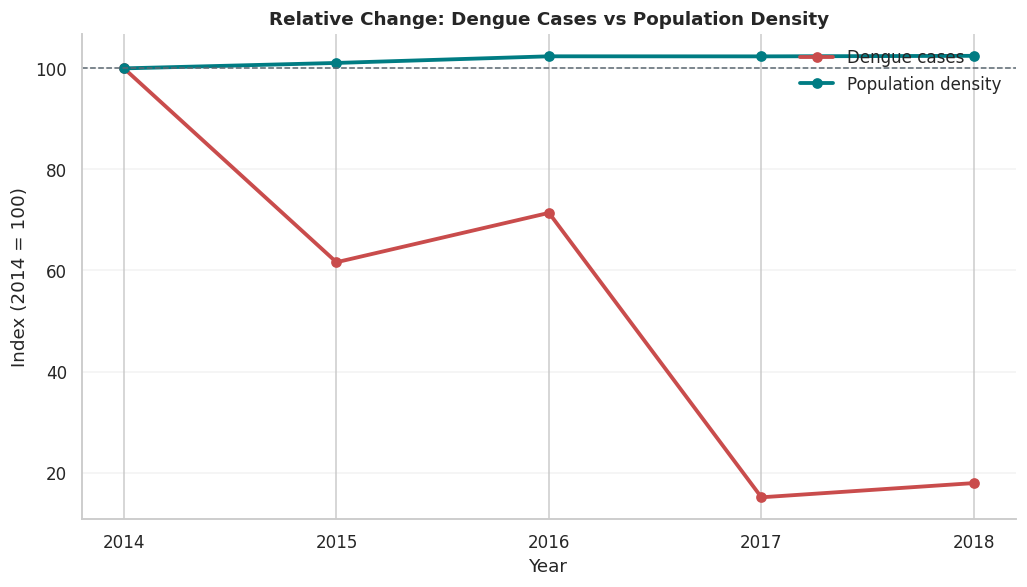

In [ ]:
# Creating an indexed comparison graph
trend_comparison = annual_analysis[["year", "total_dengue_cases", "population_density"]].copy()
trend_comparison["Dengue cases"] = trend_comparison["total_dengue_cases"] / trend_comparison.iloc[0]["total_dengue_cases"] * 100
trend_comparison["Population density"] = trend_comparison["population_density"] / trend_comparison.iloc[0]["population_density"] * 100

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.plot(trend_comparison["year"], trend_comparison["Dengue cases"], marker="o", linewidth=2.5, color=COLOURS["red"], label="Dengue cases")
ax.plot(trend_comparison["year"], trend_comparison["Population density"], marker="o", linewidth=2.5, color=COLOURS["teal"], label="Population density")
ax.axhline(100, color=COLOURS["slate"], linewidth=1, linestyle="--")
ax.set(title="Relative Change: Dengue Cases vs Population Density", xlabel="Year", ylabel="Index (2014 = 100)", xticks=annual_analysis["year"])
ax.legend(loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


## Insights

Population density increased by about 2.5% from 2014 to 2018, while dengue cases fell by about 82%. The indexed chart makes this difference easy to compare even though the two variables use different units.


We will now plot the scatter graph of population density and dengue incidence. A scatter graph is suitable because it shows the relationship between two numerical variables, with one point for each year


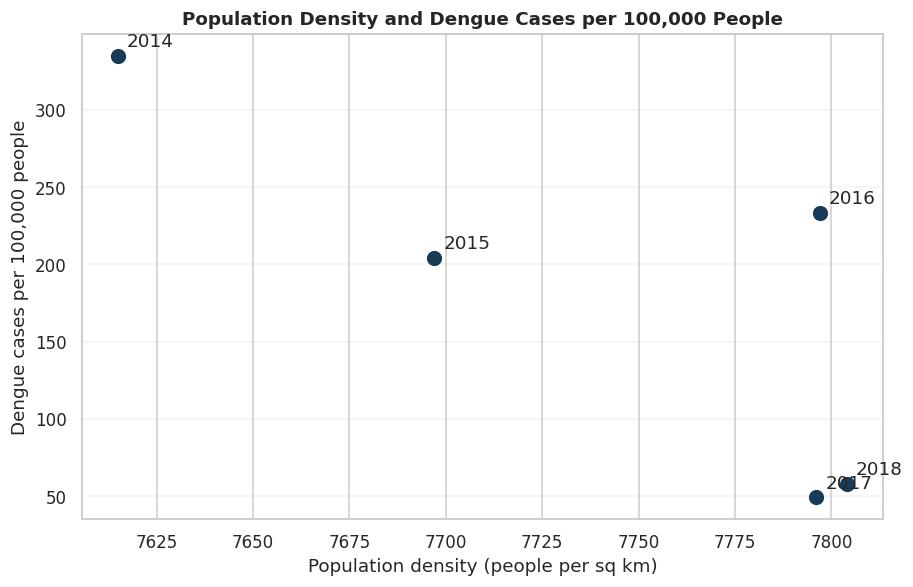

Pearson correlation: -0.797 (n = 5 years)


In [ ]:
# Creating a scatter plot for density and dengue incidence
density_rate_corr = annual_analysis["population_density"].corr(annual_analysis["dengue_cases_per_100k"])

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(annual_analysis["population_density"], annual_analysis["dengue_cases_per_100k"], s=80, color=COLOURS["navy"], zorder=3)
for _, row in annual_analysis.iterrows():
    ax.annotate(str(int(row["year"])), (row["population_density"], row["dengue_cases_per_100k"]), xytext=(6, 6), textcoords="offset points")
ax.set(title="Population Density and Dengue Cases per 100,000 People", xlabel="Population density (people per sq km)", ylabel="Dengue cases per 100,000 people")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

print(f"Pearson correlation: {density_rate_corr:.3f} (n = {len(annual_analysis)} years)")


## Insights

The correlation between population density and dengue incidence is negative, but there are only five annual points. The scatter plot is used because it shows each year behind the correlation. This result is not enough to make a decisiiv conclusion.


# Section 4: Other Factors and Limitations

NEA reports that it carried out about one million mosquito-breeding inspections in 2018 and found about 18,000 breeding habitats ([NEA, 2019](https://www.nea.gov.sg/media/news/news/index/nea-urges-continued-vigilance-to-avoid-surge-in-dengue-cases-in-2019)). this suggests that vector control may also matter.

However, I could not find a consistent monthly national inspection dataset for 2014 to 2018, so it is not added to the numerical analysis. There is also HDB town population data, but the dengue data used here is national. combining town population with national dengue totals would not be a valid local comparison.


# Conclusion

Dengue activity changed much more than national population density from 2014 to 2018. Rainfall, temperature and humidity have weak relationships with monthly dengue cases, even after one- and two-month delays. National population density also does not explain the large change in dengue cases.

The results suggest that weather and national population density may be background factors, but they do not explain dengue activity on their own. Other factors such as local mosquito levels, virus type, imported infections, human behaviour and vector-control work may also be important.


In [ ]:
# Running final validation checks
print("FINAL VALIDATION")
print(f"Monthly observations: {len(merged_df)}")
print(f"Monthly missing values: {merged_df.isna().sum().sum()}")
print(f"Duplicate months: {merged_df['month'].duplicated().sum()}")
print(f"Annual population observations: {len(annual_analysis)}")
assert len(merged_df) == 60
assert merged_df.isna().sum().sum() == 0
assert len(annual_analysis) == 5
print("All validation checks passed.")


FINAL VALIDATION
Monthly observations: 60
Monthly missing values: 0
Duplicate months: 0
Annual population observations: 5
All validation checks passed.


## Final Checks

- Run the notebook from a fresh kernel before exporting it as HTML.
- Submit the notebook, HTML export and the five CSV files.
- Be ready to explain weekly-to-monthly aggregation, inner merge, correlation, lag, dengue rate per 100,000 people and why correlation is not causation
